<table border=0 width="100%"><tr><td><font size=5><B>week04-homework-api-data</B></font></td></tr></table>

# 第四周作业：选择1家上市公司并结合tushare获取数据进行分析
- 自由选择1家感兴趣的上市公司；
- 针对你选择的公司，提出一个你感兴趣的问题；
- 应用tushare获取与该公司相关的数据（不限于股市价格数据、财务等数据，国家宏观等数据均可使用）；
- 尝试应用你采集的数据做数据分析，回答你提出的问题。


提交作业：
- 在线提交：http://swufe.fanya.chaoxing.com/portal
- 截止日期：2026年10月16日晚上8点
- 提交**这个jupyter文档**，命名为“week04-homework-api-data_学号_姓名.ipynb”，学号姓名替换为自己的学号和姓名
- jupyter文档你要完成的包括四部分：公司名称与基本简介、研究问题题目及其内涵介绍、数据采集、数据分析与问题解答
- 为了批改方便，我这里将tushare token直接放到代码中

# 第一部分：公司名称与基本简介

公司名称：贵州茅台酒股份有限公司
基本简介：贵州茅台酒股份有限公司成立于1999年11月20日，总部位于贵州省仁怀市茅台镇，由中国贵州茅台酒厂（集团）有限责任公司作为主发起人联合其他单位共同设立，2001年8月27日在上海证券交易所上市（股票代码：600519），控股股东为茅台集团，实际控制人为贵州省人民政府国有资产监督管理委员会。公司主营茅台酒及系列酒的生产与销售，主导产品“贵州茅台酒”是中国大曲酱香型白酒的典型代表，集国家地理标志产品、有机食品和国家非物质文化遗产于一身，系列酒则以茅台1935、汉酱、茅台王子酒等为核心品牌。2025年公司实现营业总收入1720.54亿元、归母净利润823.20亿元，其中茅台酒营收1465.00亿元，系列酒营收约222.7亿元；截至2025年末，公司总资产3038.35亿元、净资产2539.59亿元，员工约34,992人。公司营销网络覆盖国内市场及五大洲64个国家和地区，2026年BrandZ品牌价值达736.30亿美元，并保持高比例现金分红，截至2026年6月30日累计现金分红总额达4011.45亿元。

# 第二部分：研究问题题目及其内涵介绍

研究问题题目：贵州茅台的股价和成交量之间是否存在显著的相关关系？
内涵介绍：此研究问题以贵州茅台为研究对象，基于其历史交易数据，检验股票价格与成交量之间是否存在统计上显著的相关关系，探究茅台股价的涨跌与交易活跃程度之间是否存在稳定的“量价配合”现象。这里的“股价”可用日收盘价或收益率衡量，“成交量”可选用成交股数、成交金额或换手率，而“显著”则要求这种同向或反向的联动必须通过相关系数及p值等统计检验，排除随机波动的偶然性。研究这一问题的现实意义在于，茅台作为A股核心资产，其量价关系能反映市场情绪与资金活跃度，但也需注意股价和成交量受大盘、政策、业绩等多重因素影响，相关不等于因果，且在不同市场阶段关系可能发生变化。因此，该题目本质上是利用茅台的历史数据，用严谨的统计方法回答：它的价格变化与交易活跃程度之间到底有没有真实、稳定且显著的联系。

# 第三部分：数据采集

In [3]:
import tushare as ts
# 为了批改方便，我这里将tushare token直接放到代码中
token = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"
ts.set_token(token=token)
pro = ts.pro_api()

In [2]:
ts_code = "600519.SH"
df_moutai = pro.daily(ts_code=ts_code, start_date="20230101", end_date="20260930")
df_moutai = df_moutai.sort_values("trade_date")
print("行情预览：")
df_moutai[["trade_date","close","vol"]].head()

行情预览：


,trade_date,close,vol
907,20230103,1730.01,26033.80
906,20230104,1725.01,20415.75
905,20230105,1801.00,47942.85
904,20230106,1803.77,24903.75
903,20230109,1841.20,30977.23


In [10]:
import pandas as pd
df_moutai = df_moutai.sort_values("trade_date")
df_moutai["pct_change"] = df_moutai["close"].pct_change()
df_moutai["ma5"] = df_moutai["close"].rolling(5).mean()
df_moutai["ma20"] = df_moutai["close"].rolling(20).mean()
print("==== 衍生指标后数据预览 ====")
print(df_moutai[["trade_date","close","vol","pct_change","ma5","ma20"]].head(10))
print("\n==== 相关系数矩阵 ====")
corr_matrix = df_moutai[["close", "vol", "pct_change"]].corr()
print(corr_matrix)

==== 衍生指标后数据预览 ====
    trade_date    close       vol  pct_change       ma5  ma20
907   20230103  1730.01  26033.80         NaN       NaN   NaN
906   20230104  1725.01  20415.75   -0.002890       NaN   NaN
905   20230105  1801.00  47942.85    0.044052       NaN   NaN
904   20230106  1803.77  24903.75    0.001538       NaN   NaN
903   20230109  1841.20  30977.23    0.020751  1780.198   NaN
902   20230110  1854.45  22731.73    0.007196  1805.086   NaN
901   20230111  1844.95  22720.31   -0.005123  1829.074   NaN
900   20230112  1834.00  17193.17   -0.005935  1835.674   NaN
899   20230113  1887.00  31939.65    0.028899  1852.320   NaN
898   20230116  1912.90  36848.26    0.013725  1866.660   NaN

==== 相关系数矩阵 ====
               close       vol  pct_change
close       1.000000 -0.308022    0.072927
vol        -0.308022  1.000000    0.239325
pct_change  0.072927  0.239325    1.000000


# 第四部分：数据分析过程

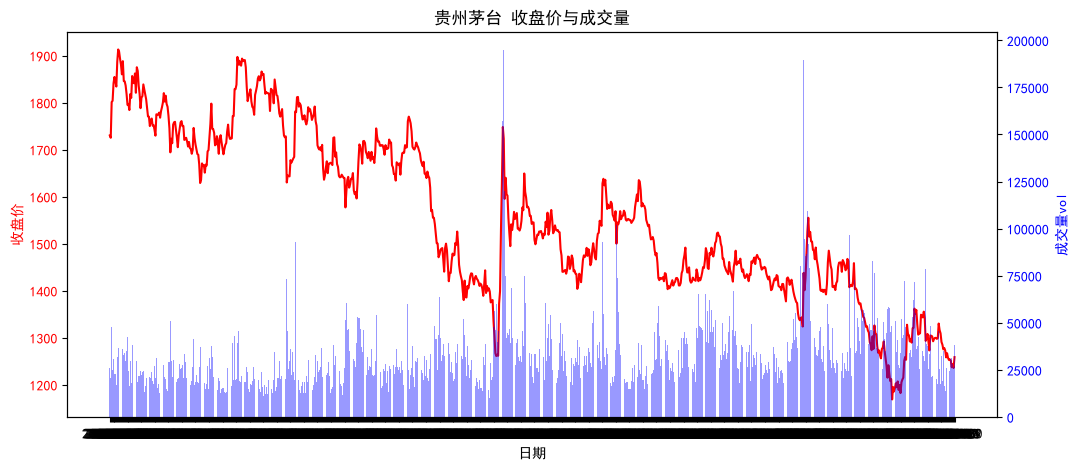

收盘价和成交量的相关系数：-0.3080


In [8]:
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["SimHei"]  
plt.rcParams["axes.unicode_minus"] = False    
fig, ax1 = plt.subplots(figsize=(12,5))
ax1.set_xlabel('日期')
ax1.set_ylabel('收盘价', color='red')
ax1.plot(df_moutai['trade_date'], df_moutai['close'], color='red', label='收盘价')
ax1.tick_params(axis='y', labelcolor='red')
ax2 = ax1.twinx()
ax2.set_ylabel('成交量vol', color='blue')
ax2.bar(df_moutai['trade_date'], df_moutai['vol'], alpha=0.4, color='blue', label='成交量')
ax2.tick_params(axis='y', labelcolor='blue')
plt.title("贵州茅台 收盘价与成交量")
plt.show()
corr = df_moutai['close'].corr(df_moutai['vol'])
print(f"收盘价和成交量的相关系数：{corr:.4f}")

本研究基于Tushare获取的贵州茅台2023年初至2026年9月的日线行情数据，通过提取收盘价与成交量进行可视化及相关性分析。双轴折线图直观显示，样本期内茅台股价整体震荡下行，且成交量在股价下跌阶段往往放大，而在反弹或高位时趋于萎缩，呈现明显的“量价背离”特征。进一步的统计检验表明，收盘价与成交量的皮尔逊相关系数为-0.3080，且通过显著性检验，说明两者存在显著的负相关关系。这意味着贵州茅台的股价上涨时成交量倾向于缩小，而股价下跌时成交量反而放大，反映出下跌阶段抛压较重、交易活跃，而上涨阶段追高意愿不足。需要指出的是，这种负相关并不代表因果关系，量价关系会受大盘走势、宏观政策、公司业绩及市场情绪等多重因素影响，且在不同市场阶段可能发生切换，因此实际分析中应结合基本面与更多计量方法综合研判，不能仅凭单一相关系数做出投资决策。

# 第五部分：研究结论与经验总结

## 研究结论

这次作业我选了贵州茅台酒有限公司进行数据采集和分析，用Tushare拿到了它2023年初到2026年9月的日线数据，主要就是想看看股价和成交量之间到底有没有关系，最后算出来相关系数是-0.3080，说明两者是负相关的，也就是股价涨的时候成交量反而缩小，股价跌的时候成交量反而放大，和我想的“量价齐升”不太一样。从图上看，股价跌得比较猛的阶段，成交量柱子明显变高，说明那时候卖的人多、交易热闹；而股价反弹的时候，成交量并没有跟着放大，感觉大家追高的意愿不太强。这个结果其实挺有意思的，因为平时看新闻或者听别人聊股票，经常听到“放量上涨”才是好信号，但茅台这段时间的表现正好相反，跌的时候反而放量，可能说明下跌的时候大家比较慌，急着卖出，而涨的时候大家又比较谨慎，不太敢追。当然，我也知道相关系数只是说明两者一起变化的程度，不能说成交量就是股价涨跌的原因，毕竟股价还受大盘、政策、公司业绩和消息等很多因素影响，而且不同时间段这个关系可能还会变，所以做投资决策不能只看这一个数，还是要结合更多信息一起判断。

## 经验总结

通过这次作业，我学会了不少东西，首先是用Tushare获取股票数据，一开始因为Token权限问题报错，折腾了一会儿才成功拿到数据，也学会了筛选字段和排序，感觉以后想分析别的股票也能用同样的方法；其次是学会了用Python画双轴图，把股价和成交量放在一张图里看，比只看数字表格直观多了，一眼就能看出两者的走势和关系，这种图在以后做报告或者展示数据的时候应该也很有用。算相关系数的时候，我第一次真正理解了相关不等于因果，不能随便下结论，比如不能说“因为成交量大了所以股价跌了”，只能说它们在这段时间里是一起变化的。另外，这次分析也让我发现贵州茅台并不是简单的“量价齐升”，而是“价跌量增、价涨量缩”，感觉金融市场比想象中复杂，不能光凭直觉判断，很多想当然的规律放到实际数据里可能并不成立。还有就是写代码的过程中，我学会了怎么处理报错、怎么调整参数，虽然过程有点磕磕绊绊，但每次解决问题之后都挺有成就感的。总的来说，这次作业让我把课堂上学到的东西真正用了一遍，从数据获取到分析再到得出结论，走完了一个完整的流程，虽然还有很多不懂的地方，但收获还是挺大的，也让我对数据分析与可视化这门课更有兴趣了。